# Bank Customer Segmentation: RFM Analysis & Machine Learning Clustering

**Latar Belakang & Objektif Bisnis:**
Memahami perilaku nasabah adalah kunci dalam industri perbankan untuk meminimalkan *churn rate* dan memaksimalkan *customer lifetime value*. Proyek ini menganalisis jutaan baris data transaksi untuk memetakan nasabah ke dalam segmen-segmen yang dapat ditindaklanjuti (*actionable segments*).

**Metodologi yang Digunakan:**
1. **Data Preprocessing & Cleaning:** Penanganan nilai kosong dan konversi tipe data spasial/waktu.
2. **RFM Feature Engineering:** Mengekstraksi metrik *Recency* (Kapan terakhir bertransaksi), *Frequency* (Seberapa sering), dan *Monetary* (Total nominal transaksi) ditambah dengan rata-rata saldo (*Mean Balance*).
3. **K-Means Clustering:** Menemukan jumlah segmen optimal menggunakan *Elbow Method* & *Silhouette Score*, lalu mengelompokkan data berskala (*scaled data*).
4. **Business Profiling:** Menerjemahkan hasil matematis dari *cluster* menjadi "Customer Persona" untuk rekomendasi strategi bisnis.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import timedelta
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')


In [15]:
#Set Style for all plots
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

In [19]:
#Step 1 Load & Basic Data Cleaning
print("1. Loading...& Data Cleaning...")
df = pd.read_csv("bank_transactions.csv")
df.dropna(subset=['CustomerID','TransactionDate','TransactionAmount (INR)','CustAccountBalance'], inplace=True)

# BIARKAN PANDAS MENEBAK FORMATNYA SECARA OTOMATIS:
# Hapus parameter format='%d/%m/%y' agar tidak error kalau format tanggalnya ternyata berbeda
df['TransactionDate'] = pd.to_datetime(df['TransactionDate'], errors="coerce", infer_datetime_format=True)


# Cek apakah data masih ada sebelum melanjutkan
df.dropna(subset=['TransactionDate'], inplace=True)
print(f"Sisa Baris Setelah Filter Tanggal {len(df)}") # Pastikan angkanya tidak 0!

1. Loading...& Data Cleaning...
Sisa Baris Setelah Filter Tanggal 1046198


In [20]:
#Step 2 RFM & Feature Engineering
print("2. RFM & Feature Engineering...")
snapshot_date = df['TransactionDate'].max() + timedelta(days = 1)

rfm = df.groupby(['CustomerID']).agg({
    'TransactionDate': 'max',
    'TransactionID': 'count',
    'TransactionAmount (INR)': 'sum',
    'CustAccountBalance': 'mean'
}).reset_index()

# Hitung Recency (selisih hari) di luar fungsi groupby agar tipe datanya pasti integer
rfm['Recency'] = (snapshot_date - rfm['TransactionDate']).dt.days

# Hapus kolom TransactionDate yang asli karena sudah diganti dengan Recency
rfm.drop('TransactionDate', axis=1, inplace=True)

rfm.rename(columns={
    'TransactionID': 'Frequency',
    'TransactionAmount (INR)': 'MonetaryValue',
    'CustAccountBalance': 'MeanBalance'
}, inplace=True)

# Pastikan paksa semua kolom menjadi numerik (kalau ada error akan jadi NaN lalu diisi 0)
for col in ['Recency', 'Frequency', 'MonetaryValue', 'MeanBalance']:
    rfm[col] = pd.to_numeric(rfm[col], errors='coerce').fillna(0)

2. RFM & Feature Engineering...


In [21]:
#Step 3 Preprocessing (log transform & scaling)
print("3. Preprocessing (log transform & scaling)...")
#Log transform to handle extreme right-skewness in financial data
rfm_log = rfm[['Recency', 'Frequency', 'MonetaryValue', 'MeanBalance']].copy()
# Sekarang penambahan float + 0.1 akan aman karena semuanya sudah pasti angka
rfm_log = np.log10(rfm_log + 0.1)

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)
rfm_scaled = pd.DataFrame(rfm_scaled, columns=rfm_log.columns)


3. Preprocessing (log transform & scaling)...


4. Finding Optimal K (Elbow Method & Silhouette)...


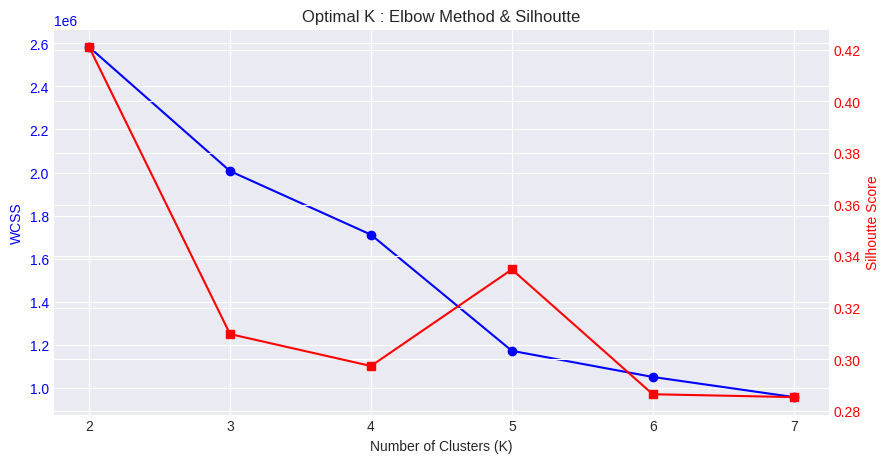

In [24]:
# STEP 4: FINDING OPTIMAL K (ELBOW METHOD & SILHOUETTE)
print("4. Finding Optimal K (Elbow Method & Silhouette)...")
# Di portofolio, bagian ini wajib ada untuk nunjukin lu tau alasan milih jumlah cluster
wcss = []
silhouette_scores = []
K_range = range(2, 8) # Test 2 to 7 clusters

# Limit sample for silhouette score if dataset is huge (to save computation time)
sample_size = min(10000, len(rfm_scaled))
rfm_scaled_sample = rfm_scaled.sample(n=sample_size, random_state=42)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

    #kalkulasi silhoutte nya
    labels = kmeans.predict(rfm_scaled_sample)
    silhouette_scores.append(silhouette_score(rfm_scaled_sample, labels))

# Plot Elbow and Silhouette (Visualisasi krusial untuk metodologi)
fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(K_range, wcss, 'bo-', label="WCSS (ELBOW)")
ax1.set_xlabel('Number of Clusters (K)')
ax1.set_ylabel('WCSS', color='b')
ax1.tick_params('y', colors='b')

ax2 = ax1.twinx()
ax2.plot(K_range, silhouette_scores, 'rs-', label="Silhouette Score")
ax2.set_ylabel('Silhoutte Score', color='r')
ax2.tick_params('y', colors='r')

plt.title('Optimal K : Elbow Method & Silhoutte')
plt.show()

In [25]:
# STEP 5: FINAL K-MEANS MODELING
# Asumsi berdasarkan plot di atas, k=4 adalah yang paling optimal
print("5. Final K-Means Modeling...")
optimal_k = 4
final_kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
rfm['Cluster'] = final_kmeans.fit_predict(rfm_scaled)

5. Final K-Means Modeling...


6. Cluster Profiling & Visualization...


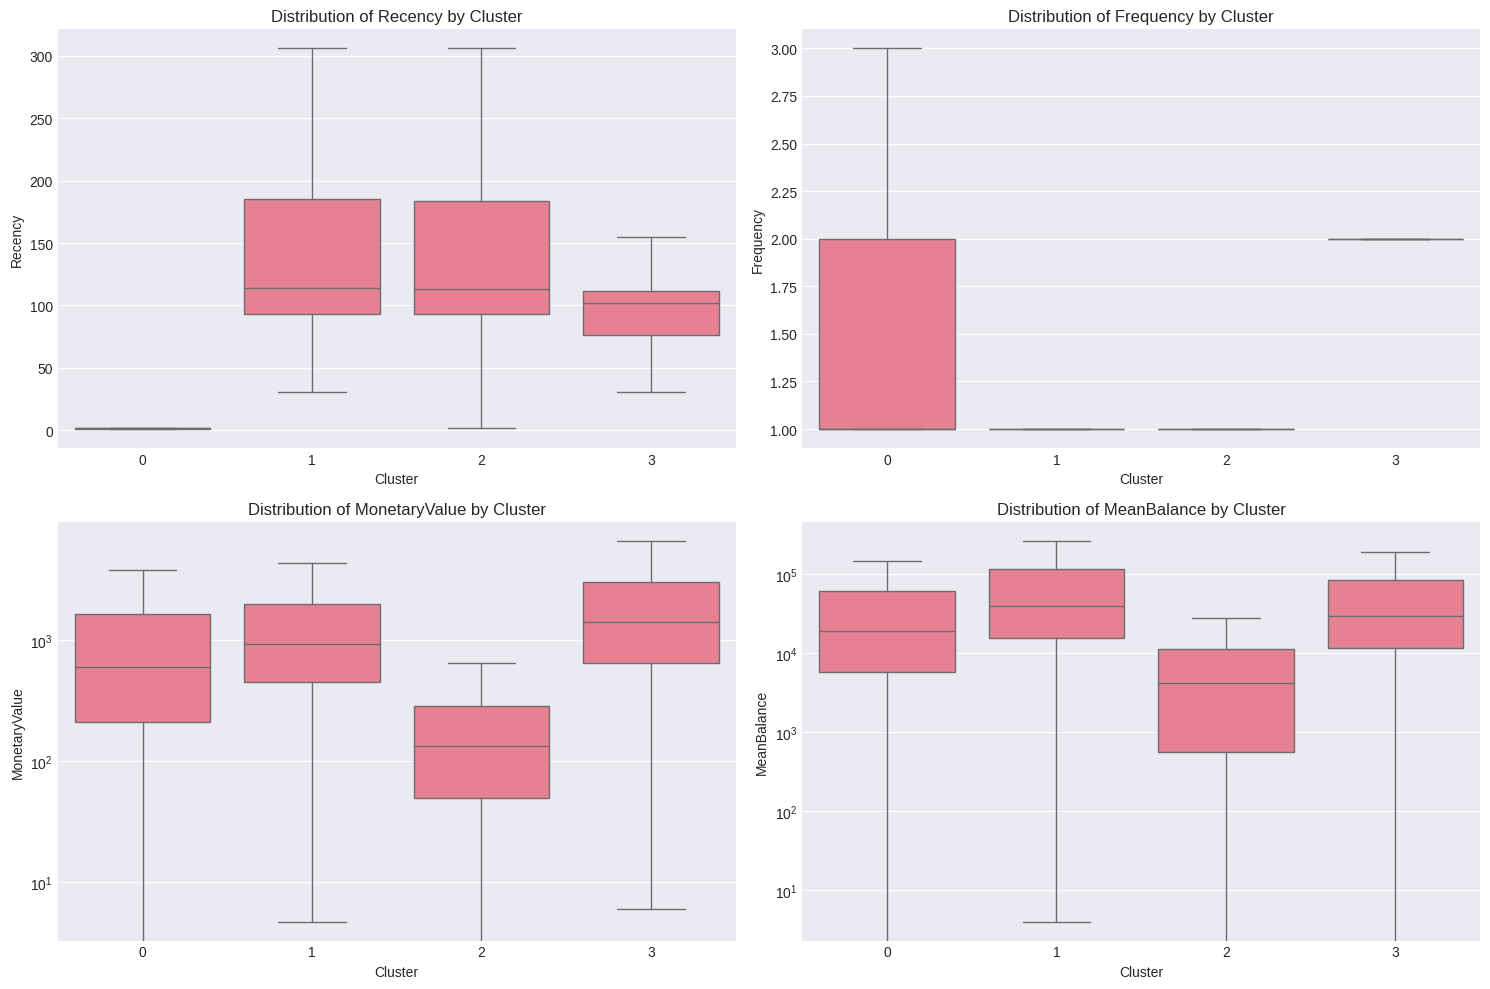

In [26]:
# STEP 6: CLUSTER PROFILING & VISUALIZATION
print("6. Cluster Profiling & Visualization...")
# Boxplots: Cara terbaik untuk membandingkan distribusi tiap fitur antar cluster
features = ['Recency', 'Frequency', 'MonetaryValue', 'MeanBalance']

plt.figure(figsize=(15, 10))
for i, feature in enumerate(features, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(x='Cluster', y=feature, data=rfm, showfliers=False) # Hide fliers for cleaner view
    plt.title(f"Distribution of {feature} by Cluster")
    if feature in ['MonetaryValue', 'MeanBalance']:
        plt.yscale('log')

plt.tight_layout()
plt.show()

In [28]:
# STEP 7: ASSIGNING PERSONAS & EXPORTING
# Interpretasi statis (Lu sesuaikan logic ini setelah melihat hasil boxplot lu sendiri)
def assign_persona(row):
  # Contoh logic sederhana, harus disesuaikan dengan rata-rata cluster lu
  if row['Cluster'] == 0: return "High - Value Loyal"
  elif row['Cluster'] == 1: return "New / Low Spend"
  elif row['Cluster'] == 2: return "Churn Risk (High Recency)"
  else: return "Average Spenders"

rfm['Persona'] = rfm.apply(assign_persona, axis=1)

# Export hasil ke CSV agar siap di-import ke Tableau/PowerBI
rfm.to_csv("rfm_segmented_customers.csv", index=False)
print('Pipeline Selesai, Data Berhasil Dikirim ke "rfm_segmented_customers.csv"')

Pipeline Selesai, Data Berhasil Dikirim ke "rfm_segmented_customers.csv"
